# Model training and evaluation

Train and evaluate the PM2.5 model (Phases I-J). A Random Forest baseline is compared with a tuned XGBoost model, always scored on the spatial folds defined in notebook 08, with the random folds kept as the optimistic reference. Headline numbers come from pooled out-of-fold predictions on the µg/m³ scale.

In [2]:
%load_ext autoreload
%autoreload 2

## Imports

In [3]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yaml
import joblib
import sklearn
import xgboost
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV, KFold, RandomizedSearchCV
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

import monitoring_deserts.models.spatial_cv as spatial_cv

## Configuration

In [6]:
# Generic settings
with open("../configs/project_config.yaml") as f:
    gen_config = yaml.safe_load(f)

CV_DATA_DIR = Path(gen_config["data_dir"]["clean"]) / "cross_validation" # outputs of notebook 08
PROCESSED_DATA_DIR = Path(gen_config["data_dir"]["processed"]) # The data/processed/ should have no subdirs
MODELS_DIR = Path(gen_config["data_dir"]["models"])
PLOTS_DIR = Path(gen_config["output_dir"]["plots"]) / "model_training"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

# Cross-validation settings, as saved by notebook 08
with open("../configs/cross_validation_metadata.yaml") as f:
    cv_config = yaml.safe_load(f)

RANDOM_STATE = cv_config["random_state"]
N_FOLDS = cv_config["n_folds"]

# Station-month table from notebook 7 (cleaned, with the log-transformed target)
analysis_df = pd.read_parquet(PROCESSED_DATA_DIR / "master_station_df.parquet")

# The parquet file loads month_of_year back as a plain integer, so restore the categorical
# dtype notebook 7 gave it (XGBoost only treats it as categorical with enable_categorical=True)
analysis_df["month_of_year"] = pd.Categorical(analysis_df["month_of_year"], categories=range(1, 13))

# Reuse the exact blocks and folds of notebook 08 (re-clustering could give different blocks)
station_folds = pd.read_parquet(CV_DATA_DIR / "station_blocks_folds.parquet")
analysis_df = analysis_df.merge(station_folds[["station_id", "spatial_block_id", "spatial_fold"]],
                                on="station_id", how="left", validate="many_to_one")
assert analysis_df["spatial_fold"].notna().all(), "stations missing from the saved fold table"

gkf_splits = [(np.where(analysis_df["spatial_fold"] != k)[0], np.where(analysis_df["spatial_fold"] == k)[0])
              for k in range(N_FOLDS)]
random_splits = list(KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE).split(analysis_df))

## Step 1 - Choose features

In [7]:
# Cyclic encoding the month_of_year for random forest
analysis_df["sin_month"] = np.sin(2 * np.pi * analysis_df["month_of_year"].astype(int) / 12)
analysis_df["cos_month"] = np.cos(2 * np.pi * analysis_df["month_of_year"].astype(int) / 12)

rfr_feature_cols = ["no2", "aai",
                    "total_precipitation", "temperature", "dew_point",
                    "u_wind", "v_wind", "wind_magnitude",
                    "boundary_layer_height", "surface_pressure", "relative_humidity",
                    "sin_month", "cos_month",
                   ]
xgb_feature_cols = ["no2", "aai",
                    "total_precipitation", "temperature", "dew_point",
                    "u_wind", "v_wind", "wind_magnitude",
                    "boundary_layer_height", "surface_pressure", "relative_humidity",
                    "month_of_year",
                   ]
target_col = "log1p_pm25"

rfr_X = analysis_df[rfr_feature_cols]
xgb_X = analysis_df[xgb_feature_cols]
y = analysis_df[target_col]

## Step 2 - Random forest baseline with Group K-Fold splits

In [20]:
#rfr = RandomForestRegressor(n_jobs=-1, random_state=RANDOM_STATE)
#param_distributions = {"n_estimators" : [400, 500, 600, 700],
#                       "max_depth" : [5, 7, 10, 15, 20],
#                       "min_samples_leaf" : [5, 10, 15, 20, 25],
#                       "max_features" : [.2, .5, .7, .9],
#                      }
#baseline_search = RandomizedSearchCV(rfr, param_distributions, scoring="neg_root_mean_squared_error", 
#                                     n_jobs=-1, n_iter=20, cv=gkf_splits, 
#                                     random_state=RANDOM_STATE, verbose=1)
#baseline_search.fit(rfr_X, y);
#rfr_best = baseline_search.best_estimator_
#print(f"Best Random Forest estimator: {baseline_search.best_estimator_}")
#print(f"Lowest RMSE score: {- baseline_search.best_score_:.3f}")

In [8]:
## Save the fitted model and the results of the CV search
#joblib.dump(baseline_search.best_estimator_, MODELS_DIR / "random_forest.joblib")
#joblib.dump(baseline_search, MODELS_DIR / "baseline_search.joblib")

# Load the fitted model and search results
rfr_best = joblib.load(MODELS_DIR / "random_forest.joblib")
baseline_search = joblib.load(MODELS_DIR / "baseline_search.joblib")

print(f"Best Random Forest estimator: {baseline_search.best_estimator_}")
print(f"Lowest RMSE score: {- baseline_search.best_score_:.3f}")

Best Random Forest estimator: RandomForestRegressor(max_depth=7, max_features=0.2, min_samples_leaf=10,
                      n_estimators=400, n_jobs=-1, random_state=42)
Lowest RMSE score: 0.462


## Step 3 - Tune XGBoost

In [21]:
#xgbr = XGBRegressor(random_state=RANDOM_STATE, n_jobs=-1, enable_categorical=True,)
#param_distributions = {"n_estimators" : [100 * x for x in range(1, 11)],
#                       "max_leaves" : [x for x in range(21)],
#                       "learning_rate" : [.01, .05, .1, .15],
#                       "subsample" : [.2, .4, .5, .7, 1.],
#                      }
#xgb_search = RandomizedSearchCV(xgbr, param_distributions, scoring="neg_root_mean_squared_error", 
#                                n_jobs=-1, n_iter=20, cv=gkf_splits, 
#                                random_state=RANDOM_STATE, verbose=1)
#xgb_search.fit(xgb_X, y);
#xgb_best = xgb_search.best_estimator_
#print(f"Best XGBRegressor estimator: {xgb_search.best_estimator_}")
#print(f"Lowest RMSE score: {- xgb_search.best_score_:.3f}")

In [9]:
## Save the fitted model and the results of the CV search
#joblib.dump(xgb_search.best_estimator_, MODELS_DIR / "xgb_best.joblib")
#joblib.dump(xgb_search, MODELS_DIR / "xgb_search.joblib")

# Load the fitted model and search results
xgb_best = joblib.load(MODELS_DIR / "xgb_best.joblib")
xgb_search = joblib.load(MODELS_DIR / "xgb_search.joblib")

print(f"Best XGBRegressor estimator: {xgb_search.best_estimator_}")
print(f"Lowest RMSE score: {- xgb_search.best_score_:.3f}")

Best XGBRegressor estimator: XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.01, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=17, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=300,
             n_jobs=-1, num_parallel_tree=None, ...)
Lowest RMSE score: 0.467


In [10]:
# Check if I am on a plateau or if it makes sense to increase iterations
tmp = (pd.DataFrame(xgb_search.cv_results_)
       .sort_values(by="rank_test_score", ascending=False)[["mean_test_score", "std_test_score"]]
       .reset_index(drop=True)
      )
tmp["pos_score"] = - tmp["mean_test_score"]
tmp["n_std_from_better_score"] = (- tmp["pos_score"] + tmp["pos_score"].shift(1)) / tmp["std_test_score"]
print(tmp.head(5))
# Seems like I am on a plateau. Keeping n_iter = 20                              

   mean_test_score  std_test_score  pos_score  n_std_from_better_score
0        -0.538239        0.074367   0.538239                      NaN
1        -0.526756        0.077395   0.526756                 0.148370
2        -0.521554        0.070760   0.521554                 0.073516
3        -0.521131        0.072002   0.521131                 0.005883
4        -0.516565        0.096443   0.516565                 0.047345


## Outline

1. ~~**Step 1 - Features and target.** Choose the predictor columns and the target (`log1p_pm25`, back-transformed with `np.expm1` for every quoted number). Latitude and longitude stay out of the features, otherwise the model can memorise stations instead of learning the pollution signal. The month enters as `sin_month`/`cos_month` for the Random Forest and as a categorical `month_of_year` for XGBoost.~~
2. ~~**Step 2 - Random Forest baseline.** Tune a Random Forest with `RandomizedSearchCV`, passing `gkf_splits` as `cv` and scoring with `neg_root_mean_squared_error`. This is the reference the XGBoost model has to beat on the spatial folds.~~
3. ~~**Step 3 - Tune XGBoost.** Run `RandomizedSearchCV` over `n_estimators`, `max_leaves`, `learning_rate` and `subsample` with the same folds, scoring and number of iterations, and `enable_categorical=True` for `month_of_year`. The spread of the candidate scores shows the search is on a plateau, so `n_iter` stays at 20.~~
4. ~~**Step 4 - Fold-by-fold comparison of the tuned models.** The mean search scores (RF 0.462, XGBoost 0.467 RMSE on the log scale) differ by far less than the fold-to-fold spread, so the means cannot decide between the models. Run the `best_estimator_` of each search, with its own feature matrix, through `spatial_cv.run_cross_validation` on `gkf_splits`, and compare the per-fold RMSE: the paired difference on each fold, and on how many folds each model wins. Apply the decision rule of plan v14 (Phase I step 3): a gap well inside the fold spread is a tie and the simpler Random Forest stays the definitive model. Both searches looked at these folds, so both scores are slightly optimistic in the same way; note this next to the numbers.~~
5. ~~**Step 5 - Headline metrics.** For the chosen model, compute R², RMSE and MAE on the µg/m³ scale from the pooled out-of-fold predictions (not the average of per-fold scores, which weights small folds too heavily). Keep the per-fold values as a diagnostic of how much the score varies from region to region.~~
6. ~~**Step 6 - Predicted vs observed.** Scatter plot of every held-out station-month, coloured by spatial block, with the 1:1 line. It shows whether errors come from a few regions or whole blocks, and whether the model compresses the high PM2.5 values.~~
7. ~~**Step 7 - Feature importance.** Built-in importances from the Random Forest and XGBoost, and permutation importance on the held-out spatial folds, to explain which signals drive the predictions. SHAP values were left out (stretch).~~
8. ~~**Step 8 - Random vs spatial comparison.** Score the chosen model on `random_splits` as well (same `run_cross_validation`) and put the random-CV and spatial-CV scores side by side, in text and in a small table. The gap is the methodological finding of Phase H.~~
9. ~~**Step 9 - Save.** Write `configs/model_training_metadata.yaml` (features, search spaces, best parameters, headline metrics) and the out-of-fold predictions, and decide where the fitted model is stored.~~
10. ~~**Step 10 - Baseline ladder (right after Step 9).** The Random Forest and XGBoost only have each other to be compared with, so it is unknown whether the satellite and weather features are worth having. Score three simple baselines on the same `gkf_splits`, with the same metrics and the same paired per-fold test as Step 4: (a) a constant prediction (the training mean of the target) as the floor; (b) spatial interpolation from the training stations alone, the nearest-station or inverse-distance-weighted PM2.5 of the same month, computed inside each fold from training stations only so that nothing leaks; (c) a regularised linear model (Ridge or ElasticNet) on the same features, which can extrapolate. The question is whether the Random Forest clearly beats the interpolation baseline. If it does, the features carry information and the project goes ahead with the limited claims noted in plan v14 (Phase J item 5). If it does not, the features add little beyond interpolating the stations, and the modelling result is reported as a finding while the project is reframed around the monitoring-gap analysis.~~
11. ~~**Step 11 - Definitive model.** Ridge regression ties the Random Forest on the spatial folds, so the simplest model wins (plan v14 rule). Check the tie still holds, save the fitted Ridge pipeline and its out-of-fold predictions, and record the decision, the standardised coefficients and the metrics in the metadata. Phase L loads this model.~~

## Step 4 - Fold-by-fold comparison

In [14]:
# Score the random forest regressor
rfr_cv_res, rfr_oof_pred = spatial_cv.run_cross_validation(rfr_best, rfr_X, y, gkf_splits)
# Score the xgb regressor
xgb_cv_res, xgb_oof_pred = spatial_cv.run_cross_validation(xgb_best, xgb_X, y, gkf_splits)

In [15]:
cv_comp = (rfr_cv_res
                 .merge(xgb_cv_res, on="fold", suffixes=("_rfr", "_xgb"))
                 .set_index("fold")[["rmse_rfr", "rmse_xgb"]]
                )
                
cv_comp["diff"] = cv_comp["rmse_rfr"] - cv_comp["rmse_xgb"]
mean_diff = cv_comp["diff"].mean()
std_diff = cv_comp["diff"].std()
serr_diff = std_diff / np.sqrt(len(cv_comp["diff"]))
t_stat = mean_diff / serr_diff # diff in units of standard error

if t_stat > 2:
    verdict = "XGBoost clearly better"
elif t_stat < -2:
    verdict = "Random Forest clearly better"
else:
    verdict = "tie: Random Forest kept for simplicity"

print(verdict)

Random Forest clearly better


## Step 5 - Compute overall out-of-fold metrics

In [16]:
# Compute the metrics for all held-out data points at once, instead of
# each fold computing its own metrics on its held-out points
y_obs = np.expm1(y) # to ug/m3
metrics = {
    "r2" : r2_score(y_obs, rfr_oof_pred),
    "rmse" : root_mean_squared_error(y_obs, rfr_oof_pred),
    "mae" : mean_absolute_error(y_obs, rfr_oof_pred),
}
print(f"Metrics for the random forest cross-validation: {[(k, round(v,2)) for (k,v) in metrics.items()]}")

Metrics for the random forest cross-validation: [('r2', 0.27), ('rmse', 27.38), ('mae', 15.51)]


## Step 6 - Predicted vs. observed

<Axes: xlabel='Observed PM2.5 concentration   [$\\mu$g m$^{-3}$]', ylabel='Predicted PM2.5 concentration   [$\\mu$g m$^{-3}$]'>

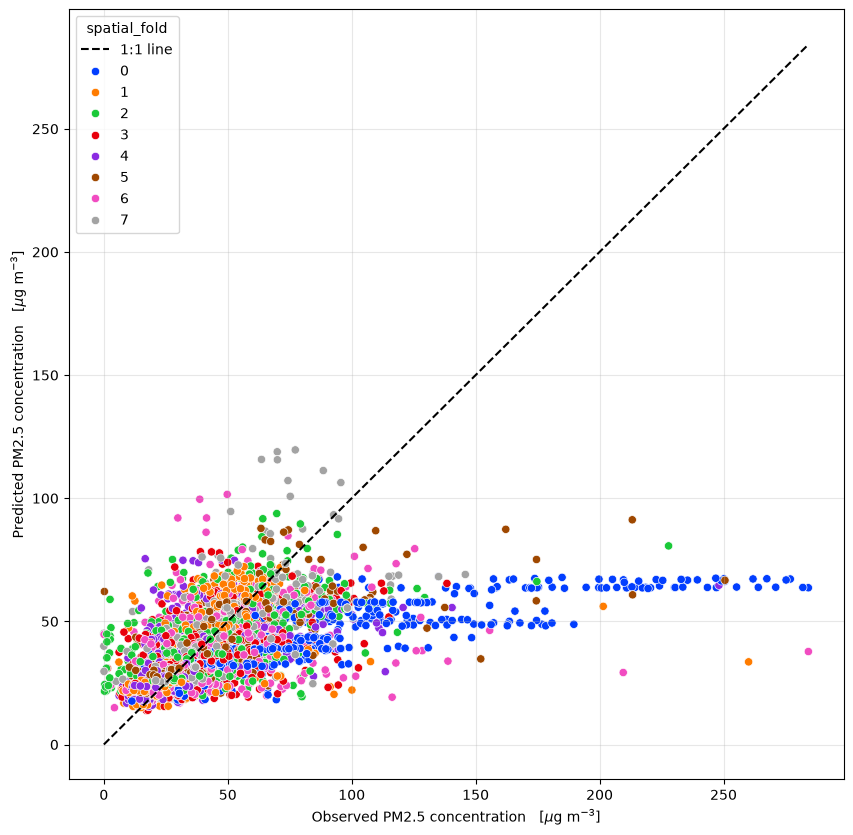

In [17]:
# Dataframe for this sub-analysis
pvo_df = analysis_df[["spatial_fold", "pm25"]].copy()
pvo_df["rfr_oof"] = rfr_oof_pred

# Plot
fig, ax = plt.subplots(figsize=(10,10))
ax.grid(alpha=.3)
ax.set_xlabel(r"Observed PM2.5 concentration   [$\mu$g m$^{-3}$]")
ax.set_ylabel(r"Predicted PM2.5 concentration   [$\mu$g m$^{-3}$]")
ax.plot([pvo_df["pm25"].min(), pvo_df["pm25"].max()], [pvo_df["pm25"].min(), pvo_df["pm25"].max()], "--k", label="1:1 line") 
ax.legend()
sns.scatterplot(pvo_df, x="pm25", y="rfr_oof", hue="spatial_fold", palette="bright", ax=ax)


## Step 7 - Feature importance

Which inputs do the models rely on when they predict regions they were not trained on? A model's built-in importances are computed on its training data, so they are only a quick look. The main analysis is permutation importance on the held-out spatial folds: for each fold, a clone of the model is fitted on the training folds, one feature (or group of features) is shuffled in the held-out rows, and the increase in RMSE is recorded. A large increase means the model needs that feature to predict unseen regions.

In [18]:
# Built-in importances: computed on the training data and on each model's own scale, so this is a
# quick look only (not comparable between the two models, and no measure of transfer to new regions).
# The forest has sin_month/cos_month where XGBoost has month_of_year, hence the NaNs.
builtin_importance = pd.DataFrame({
    "random_forest (impurity)": pd.Series(rfr_best.feature_importances_, index=rfr_X.columns),
    "xgboost": pd.Series(xgb_best.feature_importances_, index=xgb_X.columns),
})
builtin_importance.sort_values("random_forest (impurity)", ascending=False).round(3)

,random_forest (impurity),xgboost
dew_point,0.132,0.194
total_precipitation,0.127,0.083
temperature,0.106,0.099
cos_month,0.093,NaN
aai,0.090,0.049
v_wind,0.075,0.042
no2,0.075,0.055
relative_humidity,0.074,0.073
boundary_layer_height,0.070,0.059
u_wind,0.054,0.052


In [19]:
# Permutation importance on the held-out spatial folds. For every fold a clone of the model is fitted
# on the training folds; each feature is then shuffled in the held-out rows (10 times) and the increase
# in RMSE is recorded, on the log1p scale used for the tuning. sin_month and cos_month only encode the
# month together, so they are shuffled as one group; XGBoost's single month_of_year column is renamed
# to "month" so the two models line up.
rfr_perm_imp = spatial_cv.permutation_importance_by_fold(
    rfr_best, rfr_X, y, gkf_splits,
    feature_groups={"month": ["sin_month", "cos_month"]},
    n_repeats=10, random_state=RANDOM_STATE,
)
xgb_perm_imp = spatial_cv.permutation_importance_by_fold(
    xgb_best, xgb_X, y, gkf_splits,
    n_repeats=10, random_state=RANDOM_STATE,
).rename(columns={"month_of_year": "month"})

In [20]:
# Summary per model: mean increase in RMSE over the folds, its spread across the folds, and fold 0
# (the high-pollution region) on its own, since it can behave differently from the other folds
perm_summary = {
    name: pd.DataFrame({"mean": imp.mean(),
                        "std_across_folds": imp.std(),
                        "fold_0": imp.loc[0]}).sort_values("mean", ascending=False)
    for name, imp in (("Random Forest", rfr_perm_imp), ("XGBoost", xgb_perm_imp))
}
for name, table in perm_summary.items():
    print(f"{name}: increase in RMSE (log1p scale) when the feature is shuffled")
    print(table.round(4), "\n")

Random Forest: increase in RMSE (log1p scale) when the feature is shuffled
                         mean  std_across_folds  fold_0
month                  0.0201            0.0162  0.0574
total_precipitation    0.0103            0.0066  0.0177
dew_point              0.0103            0.0090  0.0290
aai                    0.0077            0.0074  0.0199
temperature            0.0074            0.0113  0.0335
relative_humidity      0.0045            0.0036  0.0086
boundary_layer_height  0.0025            0.0070  0.0170
u_wind                 0.0023            0.0033  0.0054
no2                    0.0022            0.0057  0.0061
v_wind                 0.0019            0.0029  0.0059
surface_pressure       0.0014            0.0048  0.0017
wind_magnitude         0.0005            0.0024 -0.0003 

XGBoost: increase in RMSE (log1p scale) when the feature is shuffled
                         mean  std_across_folds  fold_0
month                  0.0568            0.0489  0.1735
temperature   

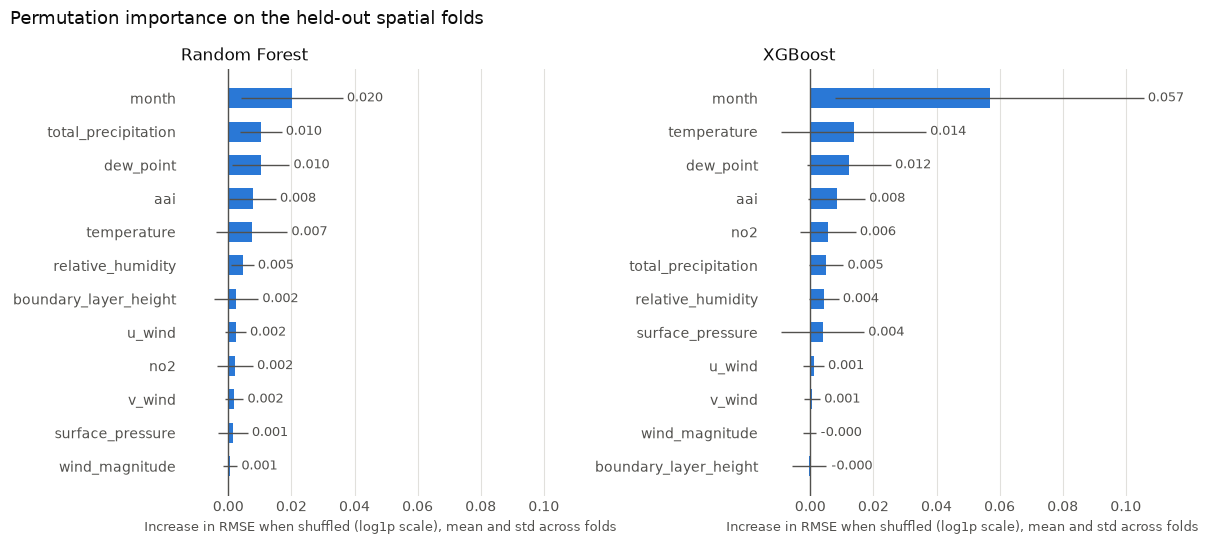

In [21]:
# Permutation importance, one panel per model on a shared x scale so the models can be compared.
# Bar = mean increase in RMSE over the folds when the feature is shuffled; thin line = standard
# deviation across the folds. One series per panel, so no legend; the x label names what is drawn.
INK, INK_MUTED, BAR_COLOR, GRID_COLOR = "#0b0b0b", "#52514e", "#2a78d6", "#e1e0dc"

x_max = max((t["mean"] + t["std_across_folds"]).max() for t in perm_summary.values())
label_pad = 0.012 * x_max

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharex=True)
for ax, (name, table) in zip(axes, perm_summary.items()):
    table = table.sort_values("mean")                       # largest bar at the top
    ax.barh(table.index, table["mean"], xerr=table["std_across_folds"], height=0.6, color=BAR_COLOR,
            error_kw={"ecolor": INK_MUTED, "elinewidth": 1, "capsize": 0})
    for row, (value, spread) in enumerate(zip(table["mean"], table["std_across_folds"])):
        ax.text(max(value, 0) + spread + label_pad, row, f"{value:.3f}",
                va="center", fontsize=9, color=INK_MUTED)
    ax.axvline(0, color=INK_MUTED, linewidth=1)             # baseline: shuffling changes nothing
    ax.set_title(name, loc="left", fontsize=12, color=INK)
    ax.set_xlabel("Increase in RMSE when shuffled (log1p scale), mean and std across folds",
                  fontsize=9, color=INK_MUTED)
    ax.grid(axis="x", color=GRID_COLOR, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=INK_MUTED, length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)

fig.suptitle("Permutation importance on the held-out spatial folds", x=0.01, ha="left", fontsize=13, color=INK)
fig.tight_layout()
fig.savefig(PLOTS_DIR / "permutation_importance.png", dpi=150, bbox_inches="tight")

**How to read the importance results**

- The numbers are the increase in RMSE on the log1p scale (the scale used for tuning), not µg/m³. Values near zero mean the model does not use the feature on held-out regions; slightly negative values are noise.
- The error bar is the spread across the 8 folds. A feature whose bar is smaller than its error bar matters in some regions and not in others.
- Correlated features hide each other: temperature, dew point, relative humidity and boundary layer height are related, and so are `u_wind`, `v_wind` and `wind_magnitude`. When one is shuffled, the model can partly recover it from its partners, so each looks less important than the group is. To test a group, shuffle it as one with `feature_groups`.
- Importance describes what the model uses, not what causes PM2.5, and a feature can be a proxy for a region.
- Fold 0 (the high-pollution region) is shown on its own in the summary table; the model may rely on different features there.

## Step 8 - Random vs spatial comparison

The chosen model (the Random Forest unless Step 4 found XGBoost clearly better) is scored once more with exactly the same hyperparameters and metrics, but on the random `KFold` splits from notebook 08. With random folds a station's other months are in the training set, so the model has already seen the place it is asked to predict; the spatial folds remove that. The difference between the two rows is the leakage of ordinary cross-validation, the methodological finding of Phase H.

In [22]:
# The model chosen in Step 4, with its own features and its spatial-fold results
if t_stat > 2:
    chosen_name, chosen_model, chosen_X = "XGBoost", xgb_best, xgb_X
    chosen_spatial_res, chosen_spatial_oof = xgb_cv_res, xgb_oof_pred
else:
    chosen_name, chosen_model, chosen_X = "Random Forest", rfr_best, rfr_X
    chosen_spatial_res, chosen_spatial_oof = rfr_cv_res, rfr_oof_pred

# Same model, same metrics, now on the random folds (the spatial folds were scored in Step 4)
chosen_random_res, chosen_random_oof = spatial_cv.run_cross_validation(chosen_model, chosen_X, y, random_splits)

In [23]:
# Pooled metrics (all held-out predictions scored together, ug/m3) and the spread of the per-fold R2
pm25_obs = analysis_df["pm25"]          # observed PM2.5; equals np.expm1 of the log1p target
schemes = {"random folds": (chosen_random_res, chosen_random_oof),
           "spatial folds": (chosen_spatial_res, chosen_spatial_oof)}
cv_comparison_table = pd.DataFrame({
    scheme: {**{f"pooled {name}": value for name, value in spatial_cv.pooled_metrics(pm25_obs, oof).items()},
             "mean fold r2": res["r2"].mean(),
             "min fold r2": res["r2"].min(),
             "max fold r2": res["r2"].max()}
    for scheme, (res, oof) in schemes.items()
}).T
cv_comparison_table.loc["difference (random - spatial)"] = (cv_comparison_table.loc["random folds"]
                                                            - cv_comparison_table.loc["spatial folds"])
print(f"{chosen_name}, same hyperparameters on both fold schemes (ug/m3)")
cv_comparison_table.round(3)

Random Forest, same hyperparameters on both fold schemes (ug/m3)


,pooled r2,pooled rmse,pooled mae,mean fold r2,min fold r2,max fold r2
random folds,0.598,20.281,12.557,0.596,0.537,0.644
spatial folds,0.268,27.379,15.514,0.283,-0.135,0.520
difference (random - spatial),0.330,-7.098,-2.957,0.313,0.672,0.123


**Reading the comparison**

- Both rows use the same model with the hyperparameters tuned on the spatial folds, so the random row is not an optimised random-CV model; the gap shows how much a leaky split flatters the same model, not the best score random CV could reach.
- The pooled values are the headline numbers; the per-fold R² range shows how much the score depends on the region held out.
- Random-CV scores overstate how well the model predicts where there is no station, because a held-out station-month almost always has the same station's other months in training. Quote the spatial row as the performance at unmonitored locations.

## Step 9 - Save the predictions and the notebook metadata

The fitted models and the search results were saved in Steps 2 and 3. Here the out-of-fold predictions go to `data/models/oof_predictions.parquet` (one row per station-month, aligned with the station-month table, with the block and fold of each row), and `configs/model_training_metadata.yaml` records the features, search spaces, best parameters, the Random Forest vs XGBoost comparison, the headline metrics and the library versions, so the results can be traced to the exact settings.

In [24]:
# Out-of-fold predictions (ug/m3), aligned with analysis_df by position; the Series get analysis_df's
# index explicitly so the concat cannot misalign if the index ever changes
oof_table = pd.concat([
    analysis_df[["station_id", "month", "spatial_block_id", "spatial_fold"]],
    pm25_obs.rename("pm25_obs"),
    pd.Series(rfr_oof_pred, index=analysis_df.index, name="pm25_rfr_spatial_oof"),
    pd.Series(xgb_oof_pred, index=analysis_df.index, name="pm25_xgb_spatial_oof"),
    pd.Series(chosen_random_oof, index=analysis_df.index, name="pm25_chosen_random_folds_oof"),
], axis=1)
assert not oof_table.isna().any().any(), "a prediction is missing: some row was in no test fold"
oof_table.to_parquet(MODELS_DIR / "oof_predictions.parquet")

In [25]:
def to_native(obj):
    """Numpy scalars and containers -> plain Python, so yaml.safe_dump accepts them."""
    if isinstance(obj, dict):
        return {str(key): to_native(value) for key, value in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [to_native(value) for value in obj]
    if isinstance(obj, np.generic):
        return obj.item()
    return obj

# Notebook metadata
paired_rf_vs_xgb = spatial_cv.paired_fold_comparison(rfr_cv_res, xgb_cv_res, column="rmse")  # forest minus XGBoost
metadata = {
    "n_stations": int(analysis_df["station_id"].nunique()),
    "n_data_points": len(analysis_df),
    "n_folds": N_FOLDS,
    "folds_and_blocks_from": "configs/cross_validation_metadata.yaml, data/clean/cross_validation/station_blocks_folds.parquet",
    "target": target_col,
    "target_transform": "log1p; predictions and metrics are back-transformed with np.expm1 (ug/m3)",
    "search_scoring": "neg_root_mean_squared_error on the log1p scale, cv = the spatial folds",
    "random_forest": {
        "features": rfr_feature_cols,
        "search_space": baseline_search.param_distributions,
        "n_iter": baseline_search.n_iter,
        "best_params": baseline_search.best_params_,
        "best_search_rmse_log1p": float(-baseline_search.best_score_),
    },
    "xgboost": {
        "features": xgb_feature_cols,
        "search_space": xgb_search.param_distributions,
        "n_iter": xgb_search.n_iter,
        "best_params": xgb_search.best_params_,
        "best_search_rmse_log1p": float(-xgb_search.best_score_),
    },
    "rf_vs_xgboost_paired_rmse": {**paired_rf_vs_xgb, "verdict": verdict,
                                  "note": "differences are random forest minus XGBoost; negative favours the random forest"},
    "chosen_model": chosen_name,
    "headline_metrics_ugm3": {
        "spatial_folds": spatial_cv.pooled_metrics(pm25_obs, chosen_spatial_oof),
        "random_folds": spatial_cv.pooled_metrics(pm25_obs, chosen_random_oof),
    },
    "per_fold_metrics_ugm3": {
        "random_forest_spatial_folds": rfr_cv_res.to_dict(orient="records"),
        "xgboost_spatial_folds": xgb_cv_res.to_dict(orient="records"),
        "chosen_model_random_folds": chosen_random_res.to_dict(orient="records"),
    },
    "known_limitation": "spatial fold 0 (the high-pollution region): see the project plan, Phase J item 5",
    "library_versions": {"scikit-learn": sklearn.__version__, "xgboost": xgboost.__version__,
                         "numpy": np.__version__, "pandas": pd.__version__},
}

with open("../configs/model_training_metadata.yaml", "w") as f:
    yaml.safe_dump(to_native(metadata), f, sort_keys=False)

## Step 10 - Baseline ladder

The Random Forest and XGBoost have so far only been compared with each other, so it is unknown whether the satellite and weather features are worth having. Three simple baselines are scored on exactly the same spatial folds, with the same metrics:

- **Constant:** the training mean of the target, the floor.
- **Interpolation from stations:** the target of the nearest training station of the same month (`n_neighbors=1`), and the inverse-distance-weighted average of the 5 nearest (`n_neighbors=5`). These use only station locations and months, no features. Only training stations are used, so nothing leaks from the held-out region.
- **Ridge regression** on the same features as the forest, with the regularisation strength chosen on the same spatial folds.

The question is whether the Random Forest clearly beats the interpolation baseline. If it does, the features carry information. If it does not, they add little beyond interpolating the stations.

In [26]:
# (a) Constant prediction: the mean of the training target in each fold
constant_res, constant_oof = spatial_cv.run_cross_validation(DummyRegressor(strategy="mean"), rfr_X, y, gkf_splits)

# (b) Interpolation from the training stations of the same month: only locations and months, no features
interp_X = analysis_df[["longitude", "latitude", "month"]]
nearest_res, nearest_oof = spatial_cv.run_cross_validation(
    spatial_cv.StationInterpolator(n_neighbors=1), interp_X, y, gkf_splits)
idw_res, idw_oof = spatial_cv.run_cross_validation(
    spatial_cv.StationInterpolator(n_neighbors=5, power=2), interp_X, y, gkf_splits)

In [27]:
# (c) Ridge regression on the same features as the forest. The scaler sits inside the pipeline, so it is
# fitted on the training folds only; alpha is chosen on the same spatial folds as the other two models
# (so its score is optimistic in the same way)
ridge_search = GridSearchCV(make_pipeline(StandardScaler(), Ridge()),
                            {"ridge__alpha": np.logspace(-2, 3, 11)},
                            scoring="neg_root_mean_squared_error", cv=gkf_splits, n_jobs=-1)
ridge_search.fit(rfr_X, y)
print(f"Best Ridge alpha: {ridge_search.best_params_['ridge__alpha']:.3g}, "
      f"search RMSE (log1p scale): {-ridge_search.best_score_:.3f}")
ridge_res, ridge_oof = spatial_cv.run_cross_validation(ridge_search.best_estimator_, rfr_X, y, gkf_splits)

Best Ridge alpha: 0.01, search RMSE (log1p scale): 0.467


In [28]:
# The ladder: pooled metrics (ug/m3, all held-out predictions scored together) and the mean fold RMSE
ladder = {
    "constant (training mean)": (constant_res, constant_oof),
    "nearest station (k=1)": (nearest_res, nearest_oof),
    "IDW of 5 nearest stations": (idw_res, idw_oof),
    "Ridge (same features)": (ridge_res, ridge_oof),
    "Random Forest": (rfr_cv_res, rfr_oof_pred),
    "XGBoost": (xgb_cv_res, xgb_oof_pred),
}
ladder_table = pd.DataFrame({
    name: {**{f"pooled {metric}": value for metric, value in spatial_cv.pooled_metrics(pm25_obs, oof).items()},
           "mean fold rmse": res["rmse"].mean()}
    for name, (res, oof) in ladder.items()
}).T
ladder_table.round(3)

,pooled r2,pooled rmse,pooled mae,mean fold rmse
constant (training mean),-0.086,33.340,20.531,29.146
nearest station (k=1),-0.109,33.693,19.854,29.691
IDW of 5 nearest stations,0.123,29.966,17.462,26.038
Ridge (same features),0.274,27.261,15.611,23.825
Random Forest,0.268,27.379,15.514,23.621
XGBoost,0.251,27.687,15.680,23.943


In [29]:
# Paired fold-by-fold test of the Random Forest against each baseline, on the per-fold RMSE (same test as
# Step 4). The difference is forest minus baseline, so a negative t favours the forest; |t| > 2 is the
# rough "clear" threshold used in Step 4 (only 8 folds, so it is a guide, not a proof).
rows = {}
for name in ["constant (training mean)", "nearest station (k=1)", "IDW of 5 nearest stations", "Ridge (same features)"]:
    test = spatial_cv.paired_fold_comparison(rfr_cv_res, ladder[name][0], column="rmse")
    if test["t_stat"] < -2:
        test["verdict"] = "Random Forest clearly better"
    elif test["t_stat"] > 2:
        test["verdict"] = "baseline clearly better"
    else:
        test["verdict"] = "no clear difference"
    rows[name] = test
paired_vs_forest = pd.DataFrame(rows).T
numeric_columns = ["mean_diff", "std_err", "t_stat", "n_folds_a_better"]
paired_vs_forest[numeric_columns] = paired_vs_forest[numeric_columns].astype(float)

# The question of this step, against the stronger of the two interpolation baselines
best_interpolation = min(["nearest station (k=1)", "IDW of 5 nearest stations"],
                         key=lambda name: ladder_table.loc[name, "pooled rmse"])
print(f"Strongest interpolation baseline: {best_interpolation}. Random Forest against it: "
      f"{paired_vs_forest.loc[best_interpolation, 'verdict']} "
      f"(t = {paired_vs_forest.loc[best_interpolation, 't_stat']:.2f})")
paired_vs_forest[numeric_columns + ["verdict"]].round(3)

Strongest interpolation baseline: IDW of 5 nearest stations. Random Forest against it: Random Forest clearly better (t = -3.36)


,mean_diff,std_err,t_stat,n_folds_a_better,verdict
constant (training mean),-5.525,1.099,-5.027,8.0,Random Forest clearly better
nearest station (k=1),-6.071,1.181,-5.140,7.0,Random Forest clearly better
IDW of 5 nearest stations,-2.417,0.720,-3.356,7.0,Random Forest clearly better
Ridge (same features),-0.204,0.508,-0.403,3.0,no clear difference


In [30]:
# Add the ladder to the metadata file written in Step 9
with open("../configs/model_training_metadata.yaml") as f:
    metadata = yaml.safe_load(f)

metadata["baseline_ladder"] = to_native({
    "metrics_ugm3": ladder_table.round(4).to_dict(orient="index"),
    "paired_rmse_forest_minus_baseline": paired_vs_forest.round(4).to_dict(orient="index"),
    "strongest_interpolation_baseline": best_interpolation,
    "ridge_best_alpha": ridge_search.best_params_["ridge__alpha"],
    "interpolation_note": "same-month training stations only, average on the log1p scale, inverse-distance weights with power 2",
})

with open("../configs/model_training_metadata.yaml", "w") as f:
    yaml.safe_dump(metadata, f, sort_keys=False)

**Reading the ladder**

- The constant baseline is the floor: an R² near zero by construction (slightly negative, since each fold's training mean differs from its test mean). Anything that cannot beat it has learned nothing transferable.
- The interpolation baselines use only where the stations are and their same-month values, never a held-out station. If the Random Forest clearly beats the better of them, the satellite and weather features carry information about PM2.5 beyond the neighbouring stations, and the project goes ahead with the limited claims noted in plan v14 (Phase J item 5). If it does not, the features add little beyond interpolating the stations; the modelling result is then reported as a finding and the project is reframed around the monitoring-gap analysis.
- Ridge shows how much of the signal is linear. It can extrapolate where trees cannot, so compare it on the high-pollution fold as well as on the pooled numbers.
- Ridge's regularisation was chosen on the same spatial folds as the two tree models, and the interpolation settings (k = 1 and k = 5) were fixed in advance, so no baseline was tuned harder than the models.
- With 8 folds the paired test is a rough guide; a verdict close to |t| = 2 should be read as borderline.

## Step 11 - Definitive model: Ridge regression

Step 4 found the Random Forest and XGBoost indistinguishable, and Step 10 found the Ridge regression indistinguishable from the Random Forest (paired RMSE test, |t| well below 2, the forest better on only 3 of 8 folds). Under the rule of plan v14 (a gap inside the noise is a tie and the simplest model wins) the definitive model is the **Ridge regression**. It also extrapolates beyond the training range, which trees cannot, and its coefficients can be read directly. This step checks that the tie still holds, saves the fitted Ridge pipeline and its out-of-fold predictions, and records the decision, with the coefficients, in the metadata. Phase L (prediction onto the grid) will load this model.

In [31]:
# The decision rests on the Step 10 paired test: Ridge must still be tied with the Random Forest
ridge_vs_forest = spatial_cv.paired_fold_comparison(ridge_res, rfr_cv_res, column="rmse")  # ridge minus forest
assert abs(ridge_vs_forest["t_stat"]) < 2, "Ridge and the forest are no longer tied: revisit the decision"

# Save the fitted pipeline (StandardScaler + Ridge, refitted on all rows by the search) and the search
ridge_best = ridge_search.best_estimator_
joblib.dump(ridge_best, MODELS_DIR / "ridge_best.joblib")
joblib.dump(ridge_search, MODELS_DIR / "ridge_search.joblib")

# Add the Ridge out-of-fold predictions (ug/m3) to the table saved in Step 9
oof_table["pm25_ridge_spatial_oof"] = ridge_oof
assert not oof_table["pm25_ridge_spatial_oof"].isna().any(), "a Ridge prediction is missing"
oof_table.to_parquet(MODELS_DIR / "oof_predictions.parquet")

# Standardised coefficients: the change in log1p(PM2.5) for one standard deviation of the feature,
# so their sizes can be compared with each other
ridge_coefficients = pd.Series(ridge_best[-1].coef_, index=rfr_X.columns).sort_values(key=abs, ascending=False)
print(f"Best alpha {ridge_search.best_params_['ridge__alpha']:.3g}; the smallest value of the grid is "
      f"{ridge_search.param_grid['ridge__alpha'].min():.3g}")
ridge_coefficients.round(4)

Best alpha 0.01; the smallest value of the grid is 0.01


temperature             -0.5326
dew_point                0.2953
relative_humidity       -0.2180
aai                      0.1718
boundary_layer_height    0.1476
surface_pressure         0.1313
wind_magnitude          -0.0870
no2                      0.0740
v_wind                  -0.0632
sin_month               -0.0470
u_wind                  -0.0465
total_precipitation     -0.0314
cos_month                0.0306
dtype: float64

In [32]:
# Record the decision in the metadata file written in Step 9
best_alpha = ridge_search.best_params_["ridge__alpha"]
alpha_grid = ridge_search.param_grid["ridge__alpha"]

with open("../configs/model_training_metadata.yaml") as f:
    metadata = yaml.safe_load(f)

metadata["definitive_model"] = to_native({
    "model": "Ridge regression (StandardScaler + Ridge)",
    "reason": ("Tied with the Random Forest on the spatial folds (paired RMSE test, ridge minus forest, |t| < 2), "
               "and the Random Forest tied XGBoost in Step 4; the simplest model with the same score wins "
               "(plan v14, Phase I step 3). It can also extrapolate beyond the training range and its "
               "coefficients are directly interpretable."),
    "features": rfr_feature_cols,
    "target": target_col,
    "best_alpha": best_alpha,
    "alpha_search_grid": alpha_grid.tolist(),
    "alpha_at_grid_edge": bool(best_alpha in (alpha_grid.min(), alpha_grid.max())),
    "standardised_coefficients_log1p": ridge_coefficients.to_dict(),
    "intercept_log1p": float(ridge_best[-1].intercept_),
    "paired_rmse_ridge_minus_forest": ridge_vs_forest,
    "pooled_metrics_ugm3": spatial_cv.pooled_metrics(pm25_obs, ridge_oof),
    "per_fold_metrics_ugm3": ridge_res.to_dict(orient="records"),
    "saved_model": "data/models/ridge_best.joblib",
    "note": ("chosen_model and headline_metrics_ugm3 above describe the tree-model comparison of Steps 4-8; "
             "this section is the model to carry forward to Phase L"),
})

with open("../configs/model_training_metadata.yaml", "w") as f:
    yaml.safe_dump(metadata, f, sort_keys=False)